# Stage 1: Setup


In [1]:
from google.colab import drive
drive.mount("/content/drive")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
import statsmodels.formula.api as smf

BASE  = "/content/drive/MyDrive/cap-and-trade-project/"
RAW   = BASE + "data/raw/"
CLEAN = BASE + "data/clean/"
OUT   = BASE + "output/"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Stage 2: Load data and define comparison groups

In [2]:
cpi_annual = pd.read_csv(CLEAN + "cpi_annual.csv", index_col="date")["cpi"]
elec       = pd.read_csv(CLEAN + "elec_panel.csv")

print("CPI:", cpi_annual.index.min(), "-", cpi_annual.index.max(), "| 2007 =", round(cpi_annual.loc[2007], 2))
print("elec:", elec.shape, elec.columns.tolist())

CPI: 1997 - 2026 | 2007 = 207.34
elec: (1224, 6) ['year', 'state', 'res_price_cents', 'generation_mwh', 'co2_mt', 'co2_rate']


In [3]:
rggi_core = ["Connecticut", "Delaware", "Maine", "Maryland", "Massachusetts",
             "New Hampshire", "New York", "Rhode Island", "Vermont"]
rggi_neighbors = ["Pennsylvania", "West Virginia"]
ca_neighbors   = ["Oregon", "Nevada", "Arizona"]

designs = {
    "RGGI":       {"treated": rggi_core,      "control": rggi_neighbors, "start": 2009},
    "California": {"treated": ["California"], "control": ca_neighbors,   "start": 2013},
}

In [4]:
elec["real_price"] = elec["res_price_cents"] * cpi_annual.loc[2007] / elec["year"].map(cpi_annual)

# Stage 3: Price gaps vs. neighbors

In [5]:
def group_means(df, treated, control, value="real_price"):
    out = (df[df["state"].isin(treated + control)]
           .assign(group=lambda d: np.where(d["state"].isin(treated), "treated", "control"))
           .groupby(["year", "group"])[value].mean()
           .unstack("group"))
    return out[["treated", "control"]]

rggi_tbl = group_means(elec, designs["RGGI"]["treated"], designs["RGGI"]["control"])
cali_tbl = group_means(elec, designs['California']['treated'], designs['California']['control'])

In [6]:
def log_gap(tbl, treated_col="treated", control_col="control"):
    return np.log(tbl[treated_col]) - np.log(tbl[control_col])

In [7]:
def mde(grp, treated_col, start, control_col="Never-treated states", end=2024):
    gap = log_gap(grp, treated_col, control_col)
    pre = gap.loc[:start - 1].dropna()
    slope, intercept = np.polyfit(pre.index, pre.values, 1)
    resid_sd = (pre - (slope * pre.index + intercept)).std(ddof=2)
    n_pre, n_post = len(pre), len(gap.loc[start:end].dropna())
    return {"program": treated_col, "resid_sd": resid_sd, "n_pre": n_pre, "n_post": n_post,
            "mde": 2.8 * resid_sd * np.sqrt(1 / n_pre + 1 / n_post)}

In [8]:
mde_elec = pd.DataFrame([mde(rggi_tbl, 'treated', 2009, 'control'), mde(cali_tbl, 'treated', 2013, 'control')])
mde_elec['expected_shares'] = [0.010367,0.019698] # from notebook 02
mde_elec["detectable"] = mde_elec["expected_shares"] >= mde_elec["mde"]
mde_elec["program"] = ["RGGI", "California"]
mde_elec

,program,resid_sd,n_pre,n_post,mde,expected_shares,detectable
0,RGGI,0.037702,8,16,0.045711,0.010367,False
1,California,0.030186,12,12,0.034505,0.019698,False


In [9]:
rggi_gap = log_gap(rggi_tbl)
ca_gap = log_gap(cali_tbl)

# Stage 4: Event study (Figure 3)

In [10]:
rggi_event = rggi_gap.copy()
rggi_event.index = rggi_gap.index - designs["RGGI"]["start"]
rggi_event = rggi_event - rggi_event.loc[-1]

In [11]:
cali_event = ca_gap.copy()
cali_event.index = ca_gap.index - designs['California']['start']
cali_event = cali_event - cali_event.loc[-1]

In [12]:
prices = pd.read_csv(CLEAN + "prices_converted.csv")

actual = prices[prices["is_forecast"] == False]
treated = actual[actual['program'].isin(['RGGI','California'])]
annual_prices = (
    treated.groupby(["program", "year"])["price_usd_mt"]
    .mean()
    .reset_index()
)

In [13]:
def expected_shares(elec, annual_prices, design, label):
    prog_prices = annual_prices[annual_prices["program"] == label][["year", "price_usd_mt"]]
    states = elec[elec["state"].isin(design["treated"])]
    out = pd.merge(states, prog_prices, on="year", how="inner")
    out["exp_share"] = out["price_usd_mt"] * out["co2_rate"] / 10 / out["res_price_cents"]   # $/mt * tons of CO2 per MWh / 10 / residential price
    return out

In [14]:
rggi_exp = expected_shares(elec, annual_prices, designs['RGGI'], 'RGGI')
rggi_exp_avg = np.log1p(rggi_exp.groupby('year')['exp_share'].mean())

In [15]:
cali_exp = expected_shares(elec, annual_prices, designs['California'], 'California')
cali_exp_avg = np.log1p(cali_exp.groupby('year')['exp_share'].mean())

In [16]:
rggi_predicted = rggi_exp_avg.copy()
cali_predicted = cali_exp_avg.copy()
rggi_predicted.index = rggi_exp_avg.index - designs["RGGI"]["start"]
cali_predicted.index = cali_exp_avg.index - designs["California"]["start"]

In [17]:
cali_predicted = cali_predicted.loc[0:]
rggi_predicted = rggi_predicted.loc[0:]

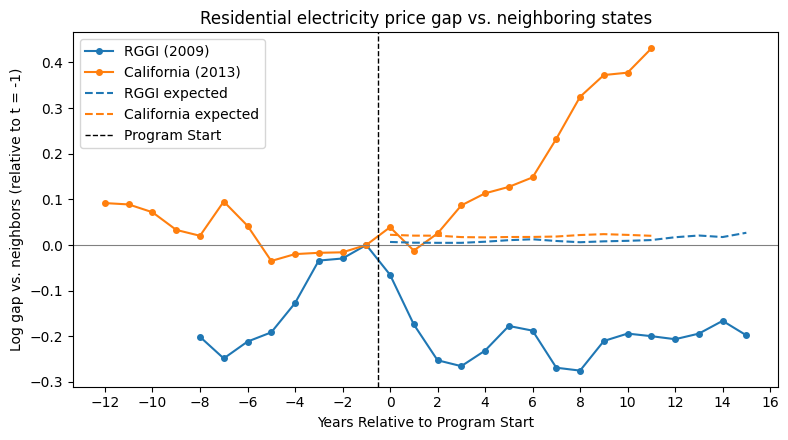

In [18]:
fig, ax = plt.subplots(figsize=(8, 4.5))

ax.plot(rggi_event.index, rggi_event.values, marker="o", markersize=4, label="RGGI (2009)")
ax.plot(cali_event.index, cali_event.values, marker="o", markersize=4, label='California (2013)')
ax.plot(rggi_predicted.index, rggi_predicted.values, color="C0", linestyle="--", label="RGGI expected")
ax.plot(cali_predicted.index, cali_predicted.values, color="C1", linestyle="--", label="California expected")

ax.axhline(0, color="gray", linewidth=0.8)

ax.axvline(-0.5, color = 'black', linewidth=1, linestyle = '--', label='Program Start')

ax.set_xlabel("Years Relative to Program Start")
ax.set_ylabel("Log gap vs. neighbors (relative to t = -1)")
ax.set_title("Residential electricity price gap vs. neighboring states")

ax.xaxis.set_major_locator(MultipleLocator(2))
ax.legend()
fig.tight_layout()
fig.savefig(OUT + "res_elec_vs_neighbors.png", dpi=400)
plt.show()

# Stage 5: Difference-in-differences (Table 2)

In [19]:
def did_panel(df, design):
    treated, control, start = design["treated"], design["control"], design["start"]
    out = df[df["state"].isin(treated + control)].copy()
    out["treated"]    = out["state"].isin(treated).astype(int)
    out["post"]       = (out["year"] >= start).astype(int)
    out["treat_post"] = out["treated"] * out["post"]
    out["log_price"]  = np.log(out["real_price"])
    return out

rggi_df = did_panel(elec, designs["RGGI"])
ca_df   = did_panel(elec, designs["California"])

In [20]:
def run_did(df, program):
    df = df.dropna(subset=["log_price"])
    res = smf.ols("log_price ~ treat_post + C(state) + C(year)", data=df).fit(
        cov_type="cluster", cov_kwds={"groups": df["state"]})
    b  = res.params["treat_post"]
    ci = res.conf_int().loc["treat_post"]
    return {"program": program, "beta": b, "pct_effect": np.exp(b) - 1,
            "se": res.bse["treat_post"], "p_value": res.pvalues["treat_post"],
            "ci_low": ci.iloc[0], "ci_high": ci.iloc[1],
            "n_states": df["state"].nunique(), "n_obs": len(df)}

In [21]:
did_results = pd.DataFrame([run_did(rggi_df, "RGGI"), run_did(ca_df, "California")])
did_results

,program,beta,pct_effect,se,p_value,ci_low,ci_high,n_states,n_obs
0,RGGI,-0.090156,-0.086211,0.087068,0.300452,-0.260806,0.080494,11,264
1,California,0.152866,0.165169,0.062922,0.015122,0.029541,0.276191,4,96


# Stage 6: Natural gas comparison

In [22]:
henry_hub = pd.read_csv(RAW + "MHHNGSP.csv")

In [23]:
henry_hub = henry_hub.reset_index()
henry_hub['observation_date'] = pd.to_datetime(henry_hub['observation_date'])
henry_hub.set_index('observation_date', inplace=True)
hh_annual = henry_hub.resample('YE').mean()

In [24]:
hh_annual['year'] = hh_annual.index.year

In [25]:
def cpi_deflation(df, cpi_annual):
  out = df.copy()
  out["date"] = pd.to_datetime(out.index, errors="coerce")
  actual = out.dropna()

  actual["cpi_year"] = actual["year"].map(cpi_annual)
  actual["real_price"] = actual["MHHNGSP"] * cpi_annual.loc[2007] / actual["cpi_year"]

  return pd.concat([actual], ignore_index=True)

In [26]:
hh_2007 = cpi_deflation(hh_annual, cpi_annual)
hh_2007.to_csv(CLEAN + 'henry_hub_annual.csv')

In [27]:
hh_2007.set_index('year',inplace=True)

In [28]:
rggi_gap = rggi_gap.rename('rggi_gap')

In [29]:
rggi_hh_merged = pd.merge(hh_2007, rggi_gap, on='year')

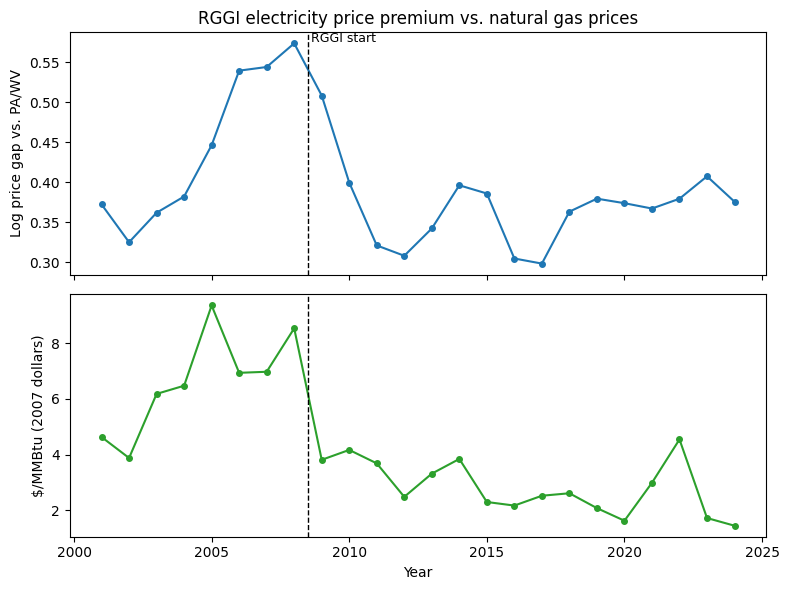

Levels: 0.64
Changes: 0.25
Lagged changes: 0.54


In [30]:
df = rggi_hh_merged.loc[2001:2024]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True)

# Top: RGGI price gap vs. neighbors
ax1.plot(df.index, df["rggi_gap"], marker="o", markersize=4, color="C0")
ax1.set_ylabel("Log price gap vs. PA/WV")
ax1.set_title("RGGI electricity price premium vs. natural gas prices")

# Bottom: real Henry Hub price
ax2.plot(df.index, df["real_price"], marker="o", markersize=4, color="C2")
ax2.set_ylabel("$/MMBtu (2007 dollars)")
ax2.set_xlabel("Year")

# Program start line in both panels
for ax in (ax1, ax2):
    ax.axvline(2008.5, color="black", linestyle="--", linewidth=1)

ax1.text(2008.6, ax1.get_ylim()[1], "RGGI start", va="top", fontsize=9)

fig.tight_layout()
fig.savefig(OUT + "rggi_gas_overlay.png", dpi=300)
plt.show()

# Correlations: levels and year-over-year changes
print("Levels:", round(df["rggi_gap"].corr(df["real_price"]), 2))
print("Changes:", round(df["rggi_gap"].diff().corr(df["real_price"].diff()), 2))
print("Lagged changes:", round(df["rggi_gap"].diff().corr(df["real_price"].diff().shift(1)), 2))

# Stage 7: Fuel mix

In [31]:
rggi_abbr = {
    'CT': 'Connecticut', 'DE':'Delaware', 'ME':'Maine',
    'MD':'Maryland', 'MA':"Massachusetts", 'NH':'New Hampshire',
    'NY':'New York', 'RI':'Rhode Island', 'VT':'Vermont'
}
pa_wv = {
    "WV":"West Virginia", "PA":"Pennsylvania"
}

In [32]:
gen_raw = pd.read_csv(RAW + "annual_generation_state.csv", skiprows=0)
gen_raw.columns = gen_raw.columns.str.strip()

gen = (gen_raw
       [(gen_raw["TYPE OF PRODUCER"].str.strip() == "Total Electric Power Industry")]
       .rename(columns={"YEAR": "year", "STATE": "state_abbr",
                        "GENERATION (Megawatthours)": "generation_mwh"})
       .query("year >= 2001 and state_abbr != 'US-TOTAL'"))
gen["generation_mwh"] = pd.to_numeric(gen["generation_mwh"].astype(str).str.replace(",", ""), errors="coerce")
gen["state"] = gen["state_abbr"].map(rggi_abbr)

gen_rggi = gen[(gen.state_abbr.isin(rggi_abbr))|(gen.state_abbr.isin(pa_wv))].copy()
gen_rggi = gen_rggi[gen_rggi['year'].isin([2001, 2008, 2020])]
gen_rggi['region'] = np.where(gen_rggi.state_abbr.isin(rggi_abbr), 'RGGI (9 states)', gen_rggi.state_abbr.map(pa_wv))

In [33]:
gen_rggi

,year,state_abbr,TYPE OF PRODUCER,ENERGY SOURCE,generation_mwh,state,region
17290,2001,CT,Total Electric Power Industry,Total,30490646,Connecticut,RGGI (9 states)
17291,2001,CT,Total Electric Power Industry,Coal,3735782,Connecticut,RGGI (9 states)
17292,2001,CT,Total Electric Power Industry,Hydroelectric Conventional,286373,Connecticut,RGGI (9 states)
17293,2001,CT,Total Electric Power Industry,Natural Gas,4088228,Connecticut,RGGI (9 states)
17294,2001,CT,Total Electric Power Industry,Nuclear,15427767,Connecticut,RGGI (9 states)
...,...,...,...,...,...,...,...
55832,2020,WV,Total Electric Power Industry,Other Gases,46561,NaN,West Virginia
55833,2020,WV,Total Electric Power Industry,Other,-16791,NaN,West Virginia
55834,2020,WV,Total Electric Power Industry,Petroleum,142408,NaN,West Virginia
55835,2020,WV,Total Electric Power Industry,Other Biomass,6457,NaN,West Virginia


In [34]:
mix = (gen_rggi
       .groupby(['region', 'year', 'ENERGY SOURCE'])['generation_mwh']
       .sum()
       .unstack('ENERGY SOURCE'))
table3 = pd.DataFrame({
    'Coal':        mix['Coal'] / mix['Total'] * 100,
    'Natural Gas': mix['Natural Gas'] / mix['Total'] * 100,
    'Nuclear':     mix['Nuclear'] / mix['Total'] * 100,
}).fillna(0)
table3['Other'] = 100 - table3.sum(axis=1)

table3 = table3.round(0).astype(int)
table3 = table3.reindex(['RGGI (9 states)', 'Pennsylvania', 'West Virginia'], level='region')
table3.to_csv(CLEAN + 'fuel_mix_table.csv')
table3

Coal  Natural Gas  Nuclear  Other
region          year                                   
RGGI (9 states) 2001    23           24       28     25
                2008    22           31       29     19
                2020     1           46       30     23
Pennsylvania    2001    57            2       38      4
                2008    53            8       35      3
                2020    10           52       33      4
West Virginia   2001    98            0        0      2
                2008    98            0        0      2
                2020    89            5        0      6